# Laboratorium 3: Od tokenów do reprezentacji wektorowych

W tym laboratorium porównamy rzadkie i gęste reprezentacje wektorowe oraz sprawdzimy, jak zachowują się w zadaniach opartych na podobieństwie tekstów.

Porównujemy:

- TF-IDF,
- `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`,
- `intfloat/multilingual-e5-small`.

Główne pytanie laboratorium:

**Czy bliskość dwóch tekstów w przestrzeni wektorowej odpowiada podobieństwu, którego potrzebujemy w konkretnym zadaniu NLP?**


## Po tych zajęciach student potrafi

- wyjaśnić różnicę między rzadką i gęstą reprezentacją wektorową;
- obliczyć i zinterpretować podobieństwo cosinusowe;
- wygenerować reprezentacje tekstu za pomocą modelu embeddingowego;
- zaimplementować wyszukiwanie najbliższych sąsiadów;
- ocenić jakość lokalnego sąsiedztwa;
- zbudować prosty benchmark wyszukiwania;
- zastosować PCA do analizy przestrzeni reprezentacji;
- rozpoznać przypadki, w których wysokie podobieństwo wektorowe nie odpowiada wymaganiom zadania;
- porównać jakość reprezentacji z jej kosztem obliczeniowym;
- uzasadnić wybór reprezentacji dla konkretnego zastosowania.


## Dane

Pracujemy na zbiorze PolEmo 2.0 wykorzystywanym w poprzednich laboratoriach.

Jeżeli istnieje plik:

```text
artifacts/polemo2_clean.parquet
```

należy użyć tej wersji danych. Jeśli pliku nie ma, proszę wrócić do Lab 1 i go przygotować.

W tym laboratorium nie używamy zbioru testowego do wyboru reprezentacji ani do strojenia eksperymentów.


## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow sentence-transformers
```

Kod startowy obejmuje wyłącznie importy, stałe i wczytanie danych. Implementacja eksperymentów należy do Państwa.


In [53]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import math
import torch
from scipy import sparse

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

from sentence_transformers import SentenceTransformer

RANDOM_STATE = 42
SAMPLE_SIZE = 1000

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_A = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_B = "intfloat/multilingual-e5-small"

pd.set_option("display.max_colwidth", 180)


In [54]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)  # tylko train, bez validation i test
print(train_df.shape)
display(train_df.head())

(5783, 7)


,text,target,split,text_norm,dup_within_split,dup_cross_split,near_dup_cross_split
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...",plus,train,"super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą staruszką , i twierdz...",False,False,False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,minus,train,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,False,False,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...",amb,train,"lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora nie mam zastrzeżeń ...",False,False,False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",zero,train,""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie trzeba wychodzić z dom...",False,False,False
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...",plus,train,"pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikatna , bardzo miła , c...",False,False,False


# Zadanie 1: TF-IDF i podobieństwo cosinusowe

Proszę rozpocząć od tekstów:

```text
A = "hotel czysty wygodny"
B = "hotel bardzo czysty"
C = "samochód szybki sportowy"
```

Proszę zaimplementować:

1. reprezentację TF-IDF;
2. tabelę wartości TF-IDF;
3. macierz podobieństwa cosinusowego;
4. wskazanie najbardziej podobnej pary.

Następnie proszę powtórzyć eksperyment dla:

```text
A = "Hotel był bardzo dobry."
B = "Obiekt noclegowy zrobił na mnie świetne wrażenie."
C = "Hotel był bardzo zły."
```

Przed uruchomieniem kodu proszę zapisać, która para powinna być najbardziej podobna według TF-IDF, a która według człowieka.


In [55]:
A = "hotel czysty wygodny"
B = "hotel bardzo czysty"
C = "samochód szybki sportowy"

A2 = "Hotel był bardzo dobry."
B2 = "Obiekt noclegowy zrobił na mnie świetne wrażenie."
C2 = "Hotel był bardzo zły."

In [56]:
class MyTfidf:
    def __init__(self, normalize: bool = True):
        self.normalize = normalize
        self.vocab_: dict[str, int] | None = None
        self.idf_: np.ndarray | None = None


    def fit(self, texts: list[str]) -> "MyTfidf":
        docs_tokens = [self._tokenize(t) for t in texts]
        self.vocab_ = self._build_vocab(docs_tokens)
        self.idf_ = self._build_idf(docs_tokens)
        return self

    def transform(self, texts: list[str]) -> np.ndarray:
        docs_tokens = [self._tokenize(t) for t in texts]
        X = self._build_tf(docs_tokens) * self.idf_
        return self._l2_normalize(X) if self.normalize else X

    def fit_transform(self, texts: list[str]) -> np.ndarray:
        return self.fit(texts).transform(texts)

    def get_feature_names_out(self) -> list[str]:
        return sorted(self.vocab_, key=self.vocab_.get)


    @staticmethod
    def _tokenize(text: str) -> list[str]:
        return re.findall(r"\w+", text.lower())

    @staticmethod
    def _build_vocab(docs_tokens: list[list[str]]) -> dict[str, int]:
        vocab = {}
        for tokens in docs_tokens:
            for word in tokens:
                vocab.setdefault(word, len(vocab))
        return vocab

    @staticmethod
    def _l2_normalize(matrix: np.ndarray) -> np.ndarray:
        norms = np.linalg.norm(matrix, axis=1, keepdims=True)
        norms[norms == 0] = 1.0
        return matrix / norms

    def _build_tf(self, docs_tokens: list[list[str]]) -> np.ndarray:
        tf = np.zeros((len(docs_tokens), len(self.vocab_)))
        for i, tokens in enumerate(docs_tokens):
            for word in tokens:
                if word in self.vocab_:
                    tf[i, self.vocab_[word]] += 1
        return tf

    def _build_idf(self, docs_tokens: list[list[str]]) -> np.ndarray:
        n_docs = len(docs_tokens)
        df = np.zeros(len(self.vocab_))
        for tokens in docs_tokens:
            for word in set(tokens):
                df[self.vocab_[word]] += 1
        return np.log((1 + n_docs) / (1 + df)) + 1

In [57]:
def cosine_sim(matrix: np.ndarray) -> np.ndarray:
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    matrix = matrix / norms
    return matrix @ matrix.T


def ranked_pairs(sim: np.ndarray, labels: list[str]) -> list[tuple[str, float]]:
    i, j = np.triu_indices(len(sim), k=1)
    order = np.argsort(sim[i, j])[::-1]
    return [(f"{labels[i[o]]}-{labels[j[o]]}", float(sim[i[o], j[o]])) for o in order]

In [58]:
def run_experiment(vectorizer, texts: list[str], labels: list[str]) -> None:
    X = vectorizer.fit_transform(texts)
    X = X.toarray() if hasattr(X, "toarray") else X

    features = vectorizer.get_feature_names_out()

    sim = cosine_sim(X)
    pair, score = ranked_pairs(sim, labels)[0]

    display(pd.DataFrame(X, index=labels, columns=features).round(3))
    display(pd.DataFrame(sim, index=labels, columns=labels).round(3))
    print(f"Najbardziej podobna para: {pair} (cos = {score:.3f})")

> **Eksperyment 1**
>
> Teksty:
> * A = "hotel czysty wygodny"
> * B = "hotel bardzo czysty"
> * C = "samochód szybki sportowy"
>
> Według człowieka najbardziej podobne powinny być teskty A i B, według TF-IDF również.

In [59]:
run_experiment(MyTfidf(), [A, B, C], ["A", "B", "C"])

,hotel,czysty,wygodny,bardzo,samochód,szybki,sportowy
A,0.518,0.518,0.681,0.000,0.000,0.000,0.000
B,0.518,0.518,0.000,0.681,0.000,0.000,0.000
C,0.000,0.000,0.000,0.000,0.577,0.577,0.577


,A,B,C
A,1.000,0.536,0.0
B,0.536,1.000,0.0
C,0.000,0.000,1.0


Najbardziej podobna para: A-B (cos = 0.536)


> Wynik taki jak oczekiwany.

> **Eksperyment 2**
>
> Teksty:
> * A = "Hotel był bardzo dobry."
> * B = "Obiekt noclegowy zrobił na mnie świetne wrażenie."
> * C = "Hotel był bardzo zły."
>
> Według człowieka najbardziej podobne powinny być teskty A i B, natomiast według TF-IDF będą to zapewne teskty A i C.

In [60]:
run_experiment(MyTfidf(), [A2, B2, C2], ["A", "B", "C"])

,hotel,był,bardzo,dobry,obiekt,noclegowy,zrobił,na,mnie,świetne,wrażenie,zły
A,0.46,0.46,0.46,0.605,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
B,0.00,0.00,0.00,0.000,0.378,0.378,0.378,0.378,0.378,0.378,0.378,0.000
C,0.46,0.46,0.46,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.605


,A,B,C
A,1.000,0.0,0.634
B,0.000,1.0,0.000
C,0.634,0.0,1.000


Najbardziej podobna para: A-C (cos = 0.634)


> No i faktycznie według TF-IDF najbardziej podobne okazały się teksty A i C, mimo że przekazują one całkiem inną opinię, są jednak zbudowane z prawie identycznych słów.

# Zadanie 2: Gęste reprezentacje wektorowe

Proszę wczytać modele `MODEL_A` i `MODEL_B` oraz wygenerować reprezentacje trzech zdań z drugiej części zadania 1.

Dla obu modeli proszę:

1. sprawdzić wymiar wektora;
2. sprawdzić typ danych;
3. wygenerować reprezentacje z normalizacją;
4. obliczyć macierz podobieństwa cosinusowego;
5. porównać kolejność podobieństw z wynikiem TF-IDF.

Model E5 wymaga prefiksów. Reguła (z karty modelu): zadania symetryczne (podobieństwo dwóch tekstów, sąsiedzi, PCA) → `query: ...` po obu stronach; wyszukiwanie (Zadanie 6) → `query: ...` dla zapytania i `passage: ...` dla dokumentów.

W tym zadaniu porównujemy zdania między sobą, więc proszę użyć `query: ...` dla wszystkich trzech zdań.

Dla obu modeli proszę dodatkowo sprawdzić `model.max_seq_length` oraz, dla tekstów z próbki z Zadania 3, jaki odsetek jest dłuższy niż okno modelu (po tokenizacji). Jak to może wpływać na kolejne zadania?

Wynik proszę zebrać w krótkiej tabeli porównawczej.


In [61]:
models = {
    "MiniLM": SentenceTransformer(MODEL_A),
    "E5": SentenceTransformer(MODEL_B),
    "TF-IDF": MyTfidf()
}

inputs = {
    "MiniLM": [A2, B2, C2],
    "E5": [f"query: {text}" for text in [A2, B2, C2]],
    "TF-IDF": [A2, B2, C2]
}

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4462.86it/s]


In [62]:
sample_df, _ = train_test_split(train_df, train_size=SAMPLE_SIZE, stratify=train_df["target"], random_state=RANDOM_STATE)
sample_df = sample_df.reset_index(drop=True)

texts = sample_df["text"].tolist()

sample_inputs = {
    "TF-IDF": texts,
    "MiniLM": texts,
    "E5": [f"query: {t}" for t in texts],
}

> Próbki do zadania 3, potrzebne tutaj do tabeli porównawczej.

In [63]:
results = []
for model_name, model in models.items():
    input_ = inputs[model_name]
    if model_name == "TF-IDF":
        output = model.fit_transform(input_)
        max_seq_length = "-"
        texts_longer_than_window = "-"
    else:
        output = model.encode(input_, normalize_embeddings=True)
        max_seq_length = f"{model.max_seq_length}"
        lens = [len(model.tokenizer(i, verbose=False)["input_ids"]) for i in sample_inputs[model_name]]
        texts_longer_than_window = f"{(np.array(lens) > model.max_seq_length).mean() * 100:.1f}"
        
    sim = cosine_sim(output)
    pairs = ranked_pairs(sim, ["A", "B", "C"])                          

    results.append({
        "Model": model_name,
        "Data Type": output.dtype,
        "Data Shape": output.shape[1],
        "Ranking": " > ".join(p for p, _ in pairs),
        "Similarity": [round(s, 3) for _, s in pairs],
        "Max Sequence Length": max_seq_length,
        "% of texts > window": texts_longer_than_window
    })

pd.DataFrame(results)

,Model,Data Type,Data Shape,Ranking,Similarity,Max Sequence Length,% of texts > window
0,MiniLM,float32,384,A-B > A-C > B-C,"[0.749, 0.378, 0.241]",128,76.7
1,E5,float32,384,A-B > A-C > B-C,"[0.927, 0.909, 0.869]",512,3.7
2,TF-IDF,float64,12,A-C > B-C > A-B,"[0.634, 0.0, 0.0]",-,-


> Oba modele embeddingowe stawiają A-B na pierwszym miejscu, więc rozpoznają podobieństwo („obiekt noclegowy” ≈ „hotel”), którego TF-IDF w ogóle nie widzi.
>
> E5 daje wszystkie wartości w wąskim przedziale 0.87–0.93.
>
> Kolejność remisów w TF-IDF jest przypadkowa. Fragment B-C > A-B nic nie znaczy przy wartościach [0.0, 0.0].
>
> MiniLM ma okno 128 tokenów i obcina aż 76.7% recenzji z próbki, więc dla większości tekstów widzi tylko ich początek. E5 (512 tokenów) obcina tylko 3.7%.

# Zadanie 3: Próbka danych i koszt reprezentacji

Proszę przygotować deterministyczną próbkę `SAMPLE_SIZE` dokumentów ze zbioru treningowego. Próbka powinna w przybliżeniu zachowywać proporcje klas.

Następnie proszę utworzyć dla tej samej próbki:

- TF-IDF z `ngram_range=(1, 2)`, `min_df=2`, `max_features=50_000`;
- reprezentacje MiniLM;
- reprezentacje E5 z prefiksem `query: ` (wersja symetryczna, używana w Zadaniach 4, 5, 7 i 8; dla Zadania 6 dokumenty trzeba będzie zakodować ponownie z prefiksem `passage: `, ten czas nie wchodzi do tabeli).

Przy pomiarze czasu proszę wyłączyć ładowanie modelu, zrobić jedną rozgrzewkę (pojedyncze uruchomienie) na małej partii i zapisać urządzenie (CPU/GPU).

Dla każdej reprezentacji proszę zmierzyć:

- czas utworzenia;
- średni czas na dokument;
- liczbę wymiarów;
- typ reprezentacji: rzadka lub gęsta;
- rozmiar reprezentacji w pamięci.

Dla macierzy rzadkiej należy uwzględnić rzeczywisty koszt struktury sparse, a nie rozmiar macierzy po konwersji do postaci gęstej.

Wynik:

| reprezentacja | czas [s] | ms/dokument | liczba wymiarów | rozmiar [MB] | typ |
|---|---:|---:|---:|---:|---|
| TF-IDF | | | | | |
| MiniLM | | | | | |
| E5 | | | | | |


In [64]:
sample_models = {
    "TF-IDF": TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000),
    "MiniLM": models["MiniLM"],
    "E5": models["E5"],
}

pd.DataFrame({
    "train": train_df["target"].value_counts(normalize=True),
    "sample": sample_df["target"].value_counts(normalize=True),
}).round(3)

,train,sample
target,,
minus,0.379,0.379
plus,0.271,0.271
amb,0.182,0.182
zero,0.168,0.168


In [65]:
torch.cuda.is_available(), torch.cuda.get_device_name(0)

(True, 'NVIDIA GeForce RTX 5070 Ti')

In [66]:
def memory_mb(X) -> float:
    if sparse.issparse(X):
        nbytes = X.data.nbytes + X.indices.nbytes + X.indptr.nbytes
    else:
        nbytes = X.nbytes
    return nbytes / 1024**2


def device_of(model) -> str:
    return "GPU" if getattr(model, "device", None) is not None and model.device.type == "cuda" else "CPU"

In [67]:
SMALL_PORTION = int(SAMPLE_SIZE * 0.01)

encoders = {
    "TF-IDF": lambda t: sample_models["TF-IDF"].fit_transform(t),
    "MiniLM": lambda t: sample_models["MiniLM"].encode(t, normalize_embeddings=True),
    "E5": lambda t: sample_models["E5"].encode(t, normalize_embeddings=True),
}

representations = {}
sample_results = []

for name, encode in encoders.items():
    inputs_ = sample_inputs[name]

    encode(inputs_[:SMALL_PORTION])

    start = time.perf_counter()
    output = encode(inputs_)
    end = time.perf_counter() - start

    representations[name] = output
    sample_results.append({
        "reprezentacja": name,
        "czas [s]": round(end, 3),
        "ms/dokument": round(end / len(inputs_) * 1000, 3),
        "liczba wymiarów": output.shape[1],
        "rozmiar [MB]": round(memory_mb(output), 3),
        "typ": "rzadka" if sparse.issparse(output) else "gęsta",
        "urządzenie": device_of(sample_models[name]),
    })

pd.DataFrame(sample_results)

,reprezentacja,czas [s],ms/dokument,liczba wymiarów,rozmiar [MB],typ,urządzenie
0,TF-IDF,0.197,0.197,15649,1.130,rzadka,CPU
1,MiniLM,0.516,0.516,384,1.465,gęsta,GPU
2,E5,1.066,1.066,384,1.465,gęsta,GPU


> TF-IDF ma znacznie więcej wymiarów niż embeddingi, a zajmuje mniej pamięci, bo macierz rzadka przechowuje tylko niezerowe wartości, więc realnie jest to pewnie tylko mały procent całej macierzy.
>
> TF-IDF na CPU jest ok. 2.5–5.5× szybszy niż embeddingi liczone na GPU.
>
> E5 jest ~2× wolniejszy od MiniLM przy tym samym wymiarze, prawdopodobnie przez dłuższe okno (512 vs 128 tokenów), czyli więcej przetwarzanych tokenów.

In [68]:
X = representations["TF-IDF"]
print(f"Odsetek zer w TF-IDF: {1 - X.nnz / (X.shape[0] * X.shape[1]):.2%}")

Odsetek zer w TF-IDF: 99.37%


> Faktycznie większość wartości w macierzy to zera.

# Zadanie 4: Najbliżsi sąsiedzi

Proszę zaimplementować funkcję:

```python
get_neighbours(embeddings, row_id, k=5)
```

która zwraca identyfikatory najbliższych dokumentów oraz wartość podobieństwa. Funkcja nie może zwracać samego dokumentu jako sąsiada. Proszę pobrać k+1 sąsiadów i usunąć z wyniku indeks równy row_id, nie zakładając, że jest on pierwszy.

Proszę wybrać trzy dokumenty z różnych klas i dla każdego porównać pięciu najbliższych sąsiadów (teksty proszę skrócić do pierwszych 200 znaków) dla:
- TF-IDF,
- MiniLM,
- E5.

Dla każdego dokumentu proszę krótko zaznaczyć:

- czy sąsiedzi są podobni tematycznie;
- czy mają tę samą etykietę sentymentu;
- czy podobieństwo wynika głównie ze wspólnego słownictwa.

In [69]:
def get_neighbours(embeddings, row_id: int, k: int = 5) -> tuple[np.ndarray, np.ndarray]:
    nn = NearestNeighbors(metric="cosine").fit(embeddings)
    dists, inds = nn.kneighbors(embeddings[row_id:row_id + 1], n_neighbors=k + 1)

    sims, inds = 1 - dists[0], inds[0]
    mask = inds != row_id
    return inds[mask][:k], sims[mask][:k]

def display_neighbours_table(row_id: int) -> None:
    doc = sample_df.loc[row_id]

    original = [{
        "id": row_id,
        "etykieta": doc['target'],
        "wylosowany tekst": doc['text']
    }]

    with pd.option_context("display.max_colwidth", 200):
                display(pd.DataFrame(original))

    print("=" * 150)

    for name, X in representations.items():
        rows = []
        ids, sims = get_neighbours(X, row_id)
        for rank, (i, s) in enumerate(zip(ids, sims), start=1):
            rows.append({
                "reprezentacja": name,
                "#": rank,
                "podobieństwo": round(s, 3),
                "etykieta": sample_df.at[i, "target"],
                "tekst": sample_df.at[i, "text"],
            })
        with pd.option_context("display.max_colwidth", 200):
            display(pd.DataFrame(rows))

        print("=" * 150)

In [70]:
query_ids = sample_df[sample_df["target"].isin(["plus", "minus", "amb"])].groupby("target").sample(1, random_state=RANDOM_STATE).index.tolist()

In [71]:
display_neighbours_table(query_ids[0])

,id,etykieta,wylosowany tekst
0,135,amb,"Bylismy w tym hotelu wraz z rodzina i 1 , 5 rocznym dzieckiem i odrazu zacze ze jesli chodzi o dziecko to jeden z lepszych hoteli duzy pokój zabaw wraz z kawiarnią , duze dwa place zabaw na zewnąt..."


,reprezentacja,#,podobieństwo,etykieta,tekst
0,TF-IDF,1,0.119,amb,"Spedzilam w hotelu Lagotel dlugi weekend od 8 do 11 maja . Musze przyznac , ze jak na hotel 3 - gwiazdkowy obiekt hotelu prezentuje sie calkiem fajnie , choc widac ze hotel ma juz swoje lata . Wra..."
1,TF-IDF,2,0.112,amb,"Hotel malowniczo położony , oblany z 2 stron wodami jeziora . Jest gdzie spacerować . Tuz przy brzegu jeziora siłownia i plac zabaw . Pokój i łazienka bardzo przestronne i nowocześnie urządzone . ..."
2,TF-IDF,3,0.109,plus,"Okolica rewelacyjna , sporo spacerowali śmy , dookoła dużo atrakcji - wystarczająco na tygodniowy wypoczynek z 1 , 5 rocznym dzieckiem ! Sam Hotel oceniamy bardzo dobrze - strefa basenów i saun su..."
3,TF-IDF,4,0.106,minus,"Właśnie wrócili śmy z "" weekendowego "" pobytu w Amaxie , skusili śmy sie akurat na ten hotel po przeczytaniu pozytywnych opinii . Wolna była willa 4 osobowa , wybrali śmy się z mężem i dzieckiem -..."
4,TF-IDF,5,0.106,amb,"Typowy Zamek - ponury i zimny . Choc w samym zamku bylo cieplo to taka stwarzal atmosfere . Nie jest to nowoczesny obiekt no bo nie moze ) ) , budowa jego siega 1298 roku takze Ci ktorzy licza na ..."


,reprezentacja,#,podobieństwo,etykieta,tekst
0,MiniLM,1,0.775,plus,"Hotel bardzo fajny szczególnie jeśli ktoś się wybiera z dziećmi mnóstwo dla nich atrakcji takich jak małpi gaj , 3 place zabaw , basen z bardzo ciepłą wodą , pokój mieli śmy 2 osobowy z dostawką s..."
1,MiniLM,2,0.760,plus,"Jeśli chcesz się poczuć wyczekiwanym gościem , to jest to idealne miejsce dla Ciebie . Znakomite warunki , fantastyczna obsługa . Bardzo ładne , nowe , czyściutkie pokoje . Byli śmy 2 dzieci i 1 d..."
2,MiniLM,3,0.758,plus,"Hotel idealny , świetnie sprawdził się dla mnie i 14 - letniego syna . Sporo atrakcji , trudno sie nudzić - odwiedzili śmy zoo , fokarium , park linowy , bunkry Bluchera w Ustce - wszystko w pakie..."
3,MiniLM,4,0.751,plus,"Świetny hotel dla rodzin z dziećmi . Spędzili śmy tu majówkę i jesteśmy zachwyceni tym miejscem , dwa duże baseny , jeden dla wszystkich gdzie jest dość głośno , bo jest dużo dzieci , drugi solank..."
4,MiniLM,5,0.735,amb,"Hotel , położony na uboczu Jastrzębiej , blisko latarni w Rozewie , jak ktoś lubi biegać to jest gdzie : ) W hotelu dwie sale zabaw dla dzieci , mała na parterze większa na - 1 , brak windy utrudn..."


,reprezentacja,#,podobieństwo,etykieta,tekst
0,E5,1,0.921,plus,"Właśnie wrócili śmy z tego Hotelu . Oceniam go bardzo dobrze , hotel czysty , zadbany , obsługa hotelowa też w porządku . Jedynym mankamentem były faktycznie wiecznie psujące się windy , ale nie p..."
1,E5,2,0.920,plus,"Hotel bardzo fajny szczególnie jeśli ktoś się wybiera z dziećmi mnóstwo dla nich atrakcji takich jak małpi gaj , 3 place zabaw , basen z bardzo ciepłą wodą , pokój mieli śmy 2 osobowy z dostawką s..."
2,E5,3,0.919,minus,"Hotel absolutnie nie trzyma poziomu 4 gwiazdek Accor . W weekend w srodku sezonu zimowego kawiarnia i bar SA NIECZYNNE , a w restauracji proponuja wino ale tylko z konsumpcja nawet dla gosci hotel..."
3,E5,4,0.919,plus,"Okolica rewelacyjna , sporo spacerowali śmy , dookoła dużo atrakcji - wystarczająco na tygodniowy wypoczynek z 1 , 5 rocznym dzieckiem ! Sam Hotel oceniamy bardzo dobrze - strefa basenów i saun su..."
4,E5,5,0.918,amb,"Plusy : + cena + restauracja , + dobre obiadokolacje dla dorosłych + duże pokoje + basen + wokół cisza i spokój + ciasteczka na pożegnanieMinusy : - animacje dla dzieci nie były prowadzone profesj..."


> **Dokument 135 [amb]**: hotel, pobyt z małym dzieckiem.
>
> **TF-IDF**
> - Tematyka: wszystko recenzje hoteli, ale tylko część dotyczy pobytu z dziećmi.
> - Etykieta: 3/5 `amb` czyli nawet dość zgodne, ale pewnie tylko przypadkiem.
> - Wspólne słownictwo: tak, niskie podobieństwa (~0.11), wynikające z kilku wspólnych słów.
>
> **MiniLM**
> - Tematyka: bardzo podobna, wszystko to opinie o hotelach dla rodzin z dziećmi.
> - Etykieta: tylko 1/5 `amb`, reszta `plus`.
> - Wspólne słownictwo: częściowo, sąsiedzi dzielą słowa tematyczne („hotel”, „dzieci”, „plac zabaw”), ale przy różnych sformułowaniach. Podobieństwo wynika bardziej z tematu niż z dokładnych słów, bo TF-IDF tych dokumentów nie znalazł.
>
> **E5**
> - Tematyka: hotele, w 3 z 5 sąsiadów pojawia się wątek dzieci, ale jest mniej dominujący niż w MiniLM.
> - Etykieta: tylko 1/5 `amb`, reszta mieszana (`plus`, `minus`).
> - Wspólne słownictwo: nie i co ciekawe podobieństwa są prawie identyczne (0.918–0.921).

In [72]:
display_neighbours_table(query_ids[1])

,id,etykieta,wylosowany tekst
0,441,minus,Niestety nie mogę zgodzić się z większością opinii pozytywnych o tym hotelu . Dlaczego : 1 . śniadania - z dodatkowego menu wybrali śmy w pierwszy dzień naleśniki dla dzieci oraz jajka w koszulkac...


,reprezentacja,#,podobieństwo,etykieta,tekst
0,TF-IDF,1,0.159,plus,"Wybrali śmy się do tego hotelu w październiku 2012 r . całą rodziną z dwójką naszych dzieci w wieku 20 i 18 lat , które wzięły ze sobą chłopaka i kolegę . Zarezerwowali śmy go około 5 tygodni wcze..."
1,TF-IDF,2,0.157,minus,Niestety ale nie mogę wyrazić pozytywnej oceny na temat Hotelu Wiktoria . Warunki jakie tam panują przypominają te z lat 90 - tych . Na pierwszy rzut oka Hotel prezentuję się całkiem nieźle . Znaj...
2,TF-IDF,3,0.156,minus,"Jestem bardzo powściągliwy jeśli chodzi o krytykowanie kogokolwiek i czegokolwiek , ale to co spotkało mnie i moją żonę w sobotę walentynkową w Dolinie Charlotty przeszło moje najśmielsze oczekiwa..."
3,TF-IDF,4,0.147,minus,"Witam . Tak jak wielu turystów w tym roku , którzy w 1 . połowie sierpnia mieli zaplanowany pobyt w tym hotelu i skorzystali z oferty różnych biur , zostali śmy niemile zaskoczeni w trakcie chck -..."
4,TF-IDF,5,0.145,minus,"Hotel piękny , w każdym detalu . Pokoje ok , mieli śmy pokój o podwyższony standardzie , był bardzo przestronny . Irytujący wentylator w łazience uruchamiający się na minutę albo i więcej . Śniada..."


,reprezentacja,#,podobieństwo,etykieta,tekst
0,MiniLM,1,0.780,plus,"Pyszne i urozmaicone śniadania . Wszystko obeszli śmy pieszo z hotelu . Obsługa hotelu załatwiła nam parking tuż za rogiem w bezpiecznym miejscu ( wcześniejsza rezerwacja ) , cena 22 euro za dobę ..."
1,MiniLM,2,0.777,minus,"Niestety nie będę polecić tego hotelu . Jedzenie okropne , to co na obiad to i na kolacje . Ryby mrożone , żadnych owoców morza . Obsługa na początku pobytu miła , później niekoniecznie . Kelnerzy..."
2,MiniLM,3,0.770,amb,"Spędzili śmy z rodziną 4 dni w Hotelu Niemcza SPA i był to pobyt Wielkanocny . Hotel ładnie położony , pokoje czyste , miła obsługa . Tutaj kończą się plusy . Pokoje są zdecydowanie za małe - nawe..."
3,MiniLM,4,0.756,minus,"Właśnie wrócili śmy z hotelu Diva Spa . Hotel jak na 4 gwiazdki przeciętny , nie do zapamiętania . Duzym minusem tego hotelu jest niestety wyżywienie - przez caly tydzień tylko raz była ryba na ob..."
4,MiniLM,5,0.756,plus,Właściwie same pozytywy przychodzą mi na myśl pisząc o tym hotelu : Jedzenie - właściwie pierwszy hotel w którym jest tak ogromny wybór potraw niezależnie czy śniadanie czy obiadokolacja - nigdy n...


,reprezentacja,#,podobieństwo,etykieta,tekst
0,E5,1,0.942,minus,"Właśnie wrócili śmy z "" weekendowego "" pobytu w Amaxie , skusili śmy sie akurat na ten hotel po przeczytaniu pozytywnych opinii . Wolna była willa 4 osobowa , wybrali śmy się z mężem i dzieckiem -..."
1,E5,2,0.933,amb,"spedzilismy w hotelu tatra 2 noce , hotel czysty , pokoje przestronne . basen , kregielnia , drink bar - strzal w dziesiatke ! brak telefonow w pokojach , w kazdej sytuacji trzeba isc do recepcji ..."
2,E5,3,0.932,minus,"Ten hotel , czasy świetności ma już dawno za sobą . Plamy na wykładzinie , odrapane ściany , zniszczone meble , dziury w firankach , ale najgorsze jest to , że jest STRASZNIE BRUDNO ! ! ! Nikt nie..."
3,E5,4,0.931,minus,Niestety ale nie mogę wyrazić pozytywnej oceny na temat Hotelu Wiktoria . Warunki jakie tam panują przypominają te z lat 90 - tych . Na pierwszy rzut oka Hotel prezentuję się całkiem nieźle . Znaj...
4,E5,5,0.931,minus,"Hotel ten pod względem czystości nie zasługuje na jedną gwiazdkę . Wykładziny brudne aż strach dziecko puścić w obawie przed grzybicą . Trafili śmy na pokój z meblami zakurzonymi , dziurą w drzwia..."


> **Dokument 441 [minus]**: negatywna recenzja hotelu - narzekanie na śniadania.
>
> **TF-IDF**
> - Tematyka: recenzje hoteli, głównie z opisem problemów podczas pobytu.
> - Etykieta: 4/5 `minus`, jedna `plus`.
> - Wspólne słownictwo: tak, np. sąsiad #2 zaczyna się prawie tak samo („Niestety… nie mogę…").
>
> **MiniLM**
> - Tematyka: skupiona na jedzeniu i śniadaniach, czyli na jednym wątku recenzji, a nie na całości.
> - Etykieta: tylko 2/5 `minus`, reszta mieszana (`plus`, `amb`).
> - Wspólne słownictwo: nie, sąsiedzi łączą się tematem, a nie konkretnymi słowami.
>
> **E5**
> - Tematyka: hotele, w których coś poszło nie tak (brud, zły stan, rozczarowanie).
> - Etykieta: 4/5 `minus`, 1/5 `amb`, czyli najlepiej oddaje negatywny wydźwięk.
> - Wspólne słownictwo: nie, ale podobieństwa znów są bardzo zbliżone (0.931–0.942).

In [73]:
display_neighbours_table(query_ids[2])

,id,etykieta,wylosowany tekst
0,273,plus,"Zdjęcia nie oddają do końca poziomu hotelu . Kiedy wszedł em do środka , szczęka mi opadła do ziemi . W recepcji super ludzie ( jeżeli ktoś nie zna języka to pracuje tam P . Karolina i Czeszka chy..."


,reprezentacja,#,podobieństwo,etykieta,tekst
0,TF-IDF,1,0.117,plus,Na wakacjach byli śmy w 4 dorosłe osoby . Lot z Warszawy bez problemów . Dojazd z lotniska zajął około 1 godzinę co przy mało klimatyzowanym autobusie było dużą ulgą . Na miejscu musieli śmy czeka...
1,TF-IDF,2,0.105,plus,"Pobyt w tym hotelu był miłym zaskoczeniem . Ładne pokoje , wszystko zadbane , miła atmosfera . Jedyne co nie zasługiwało na 5 gwiazdek to kryty basen ( wchodząc do niego uderza w nas tak silny zap..."
2,TF-IDF,3,0.099,plus,"Bardzo miła obsługa . . . młodzi ludzie znają się na rzeczy , kuchnia świetna duży wybór dań większość była naprawdę wyśmienita aż chciało się wszystkich spróbować większą ilość ale żołądek to nie..."
3,TF-IDF,4,0.098,amb,"Już drugi raz razem z chłopakiem zatrzymali śmy się w tym miejscu . Nie jest najgorsze , zwłaszcza , że jest blisko centrum i do enegry . Jeżeli ktoś chce zatrzymać się na jedną bądź dwie noce w K..."
4,TF-IDF,5,0.094,minus,Była m w tym hotelu na początku października . Po pół godz czekania na panią z recepcji okazało się że niema mojej rezerwacji . Później okazało się że zamiast zamówionego przeze mnie pokoju z prys...


,reprezentacja,#,podobieństwo,etykieta,tekst
0,MiniLM,1,0.676,amb,Nie wiem z jakiego materiału są wykonane ściany ale słuchanie o czym rozmawiają sąsiedzi nawet przy włączonym telewizorze to już przesada . Pozdrawiamy Panią Mariolę oraz towarzyszących jej dwóch ...
1,MiniLM,2,0.613,amb,"Hotel sam w sobie jest ok . Czysto , schludnie . Personel bardzo sympatyczny szczególnie obsługa baru i jadalni . Miejsce odwiedzane głównie przez Niemców w podeszlym wieku . Animacji w ciągu dnia..."
2,MiniLM,3,0.612,plus,"Warunki w hotelu bardzo przyzwoite , widok na Giewont - bajka ! , obsługa miła ( za wyjątkiem młodej blondynki z recepcji , która sprawiała wrażenie jakby klienci jej przeszkadzali ) , posiłki sma..."
3,MiniLM,4,0.594,minus,wyjazd ze znajomymi we wrześniu 2017 . Pierwsze wrażenie nie jest złe . Recepcja wygląda całkiem zachęcająco . Na wejściu przywitały nas dwie sympatyczne dziewczyny . Zapytały po angielsku z jakie...
4,MiniLM,5,0.578,amb,"Co prawda nie mieszkalismy w tym hotelu , ale przychodzilismy do restauracji i na kregle . Obiekt jest pieknie polozona , fajna nowoczesna architektura , obledny widok . . . Jedzenie pyszne , nato..."


,reprezentacja,#,podobieństwo,etykieta,tekst
0,E5,1,0.914,plus,"Hotel znajduje się w ładnym miejscu . Dookoła las , pola , łąki - szczególnie teraz bardzo mnie to zachwyciło , gdyż pięknie ta przyroda wyglądała . W recepcji bardzo miła obsługa , pokoje wygodne..."
1,E5,2,0.911,plus,Na wakacjach byli śmy w 4 dorosłe osoby . Lot z Warszawy bez problemów . Dojazd z lotniska zajął około 1 godzinę co przy mało klimatyzowanym autobusie było dużą ulgą . Na miejscu musieli śmy czeka...
2,E5,3,0.910,amb,Była m w wakacje z rodziną . Duży plus to przepyszne urozmaicone jedzenie i lokalizacja - wszędzie blisko . Jednak jeśli chodzi o ciszę i spokój to raczej nie tu - fontanna usytuowana przy hotelu ...
3,E5,4,0.909,amb,"Wrócili śmy z bardzo udanych wakacji na Gran Canarii ( sierpień 2013 ) , tym niemniej hotel nas nieco rozczarował . Animacje i hotel nastawiony na turystów z Wlkp . Brytanii i Skandynawii , animac..."
4,E5,5,0.909,plus,"Pobyt w tym hotelu był miłym zaskoczeniem . Ładne pokoje , wszystko zadbane , miła atmosfera . Jedyne co nie zasługiwało na 5 gwiazdek to kryty basen ( wchodząc do niego uderza w nas tak silny zap..."


> **Dokument 273 [plus]**: entuzjastyczna recenzja hotelu, z pochwałą obsługi recepcji.
>
> **TF-IDF**
> - Tematyka: recenzje hoteli i wyjazdów, bez wyraźnego wspólnego wątku.
> - Etykieta: 3/5 `plus`, reszta `amb` i `minus`.
> - Wspólne słownictwo: tak, ale słabe: niskie podobieństwa (~0.1) wynikają ze słów takich jak „hotel”, „pobyt”, „obsługa”.
>
> **MiniLM**
> - Tematyka: skupiona na personelu i recepcji - wzmianki o konkretnych pracownikach.
> - Etykieta: tylko 1/5 `plus`, przewaga `amb`.
> - Wspólne słownictwo: nie, sąsiedzi łączą się tematem obsługi, a nie konkretnymi słowami.
>
> **E5**
> - Tematyka: udane pobyty w hotelach i na wakacjach, ogólnie pozytywne wrażenia.
> - Etykieta: 3/5 `plus`, 2/5 `amb`, bez `minus`.
> - Wspólne słownictwo: nie, ale podobieństwa znów są bardzo zbliżone (0.909–0.914).

# Zadanie 5: Czystość sąsiedztwa

Dla dokumentu $x$:

$$
\text{purity@}k(x) = \frac{\text{liczba sąsiadów z tą samą etykietą}}{k}
$$

proszę policzyć średnią tej wartości po całej próbce (bez samego dokumentu jako sąsiada) dla k = 1, 5, 10 dla TF-IDF, MiniLM i E5. Dodatkowo proszę podać:

- punkt odniesienia: oczekiwaną purity dla losowych sąsiadów, czyli sumę kwadratów udziałów klas (`(train_df["target"].value_counts(normalize=True) ** 2).sum()`; przy rozkładzie z Lab 1 ok. 0,28);
- `purity@5` osobno dla każdej klasy.

Proszę policzyć:

- `purity@1`,
- `purity@5`,
- `purity@10`

dla TF-IDF, MiniLM i E5.

Wynik:

| reprezentacja | purity@1 | purity@5 | purity@10 |
|---|---:|---:|---:|
| TF-IDF | | | |
| MiniLM | | | |
| E5 | | | |


In [74]:
def purity_scores(embeddings, labels: np.ndarray, k: int) -> np.ndarray:
    matches = np.zeros((len(labels), k), dtype=bool)
    for row_id in range(len(labels)):
        ids, _ = get_neighbours(embeddings, row_id, k)
        matches[row_id] = labels[ids] == labels[row_id]
    return matches

In [75]:
labels = sample_df["target"].to_numpy()
ks = [1, 5, 10]

matches = {name: purity_scores(X, labels, k=max(ks)) for name, X in representations.items()}

purity_table = pd.DataFrame({
    name: {f"purity@{k}": m[:, :k].mean() for k in ks}
    for name, m in matches.items()
}).T.round(3)

baseline = (train_df["target"].value_counts(normalize=True) ** 2).sum()

display(purity_table)
print(f"Purity dla losowych sąsiadów: {baseline:.3f}")

,purity@1,purity@5,purity@10
TF-IDF,0.573,0.559,0.542
MiniLM,0.602,0.580,0.558
E5,0.687,0.665,0.642


Purity dla losowych sąsiadów: 0.279


> Wszystkie reprezentacje są wyraźnie lepsze od losowych sąsiadów, a najlepszy jest E5. MiniLM jest tylko nieznacznie lepszy od TF-IDF.
>
> Purity lekko spada wraz ze wzrostem k, bo dalsi sąsiedzi są coraz mniej podobni.

In [76]:
per_class = pd.DataFrame({name: pd.Series(m[:, :5].mean(axis=1)).groupby(labels).mean() for name, m in matches.items()}).round(3)
display(per_class)

,TF-IDF,MiniLM,E5
amb,0.249,0.264,0.334
minus,0.688,0.664,0.758
plus,0.476,0.590,0.658
zero,0.740,0.719,0.825


> Najwyższą purity ma klasa `zero`, teksty neutralne, które tutaj najczęściej są artykułami lub innymi tekstami (mało podobnymi do recenzji) różnią się stylem od recenzji, więc lepiej się grupują.
>
> Najsłabiej wypada `amb`, bo łączy pozytywne i negatywne fragmenty, więc jej sąsiedzi trafiają do `plus` i `minus`.
>
> Największą przewagę embeddingów widać dla `plus`: TF-IDF 0.476, E5 0.658.

# Zadanie 6: Miniaturowy benchmark wyszukiwania

Proszę przygotować osiem zapytań: po dwa dla każdej klasy `plus`, `minus`, `zero`, `amb`.

Dla każdego zapytania należy zdefiniować oczekiwaną klasę dokumentów. Dla klas `zero` i `amb` proszę wcześniej zapisać, co w tym zbiorze znaczy "dokument relewantny" (pomoże przejrzenie kilkunastu losowych dokumentów tych klas z próbki).

Dla E5 dokumenty z próbki proszę zakodować ponownie z prefiksem `passage: ` (zapytania z `query: `).

Wyniki proszę podać również per zapytanie. Osiem zapytań to bardzo mała próba, więc różnic mniejszych niż ok. 0,1 między reprezentacjami nie należy interpretować jako przewagi.

Następnie proszę zaimplementować wyszukiwanie dla:

- TF-IDF;
- MiniLM;
- E5.

Dla E5 zapytanie powinno być kodowane z prefiksem:

```text
query: ...
```

a dokumenty z prefiksem:

```text
passage: ...
```

Proszę zaimplementować i policzyć:

- `Precision@5`;
- `Precision@10`.

Wynik:

| reprezentacja | Precision@5 | Precision@10 |
|---|---:|---:|
| TF-IDF | | |
| MiniLM | | |
| E5 | | |

Ten benchmark jest uproszczony: etykieta sentymentu pełni rolę przybliżonej oceny relewancji.


In [77]:
lookup = []

for label in ["zero", "amb"]:
    for t in sample_df[sample_df["target"] == label].sample(10, random_state=RANDOM_STATE)["text"]:
        lookup.append({
            "label": label,
            "test": t
        })

pd.DataFrame(lookup)

,label,test
0,zero,"Dlatego niezbędne jest testowanie materiału pobranego od wielu osób . "" Te wszystkie aspekty skłoniły nas do nawiązania współpracy z grupą lekarzy ze Szpitala Wojewódzkiego i S..."
1,zero,"Badacze potrafią wprawdzie nazwać i zlokalizować geny odpowiedzialne za rzadkie choroby poliglutaminowe , wciąż jednak nie poznali mechanizmów ich powstawania . Tego zadania po..."
2,zero,""" Interesuję się medycyną regeneracyjną , szczególnie inżynierią tkankową - jej celem jest zastąpienie bądź podtrzymanie funkcji uszkodzonych tkanek lub narządów przy pomocy im..."
3,zero,"Specjalistka twierdzi , że spór o to , czym należy smarować pieczywo - masłem czy margaryną - ma długą tradycję , znacznie wybiegającą w przeszłość . Zaczął się już w latach pr..."
4,zero,"Centralne skrzydło jest jednokondygnacyjne , zlokalizowane są w nim gabinety terapeutyczne i kosmetyczne . Skrajne skrzydła ( wschodnie i zachodnie ) posiadają po cztery kondyg..."
5,zero,"„ Silne pole magnetyczne wytwarzane podczas pracy rezonansu skierowane jest wzdłuż tunelu , w którym znajduje się pacjent i wymusza na tym małym magnesie ustawienie w kierunku ..."
6,zero,"Mam pytanie odnośnie prowadzenia ciąży , czy w przypadku nadciśnienia w drugiej części ciąży i przyjęcia do siebie do szpitala wykonuje często badania np . KTG i koniecznie oce..."
7,zero,"Bo oczywiście , jak to zwykle bywa na rynku hotelowym , nie wszystkie plany i tej sieci udaje się zrealizować . Dość wspomnieć zaniechaną przez upadek inwestora budowę hotelu H..."
8,zero,"W ostatnich kilkudziesięciu latach więcej osób umiera w szpitalach lub hospicjach . Z danych GUS wynika , że w 1980 r . w szpitalu zmarło 42 , 7 proc . osób , 0 , 5 proc . w in..."
9,zero,"„ Jeżeli chcemy przewidzieć jakiś proces , to dobrze było by wiedzieć , jaka była jego historia ” - mówi dr Rafał Mostowy , naukowiec pracujący na Imperial College of London . ..."


> Relewantny dokument `zero`: tekst informacyjny bez oceny, np. fragment artykułu, opis obiektu albo pytanie, nie są one recenzjami.
>
> Relewantny dokument `amb`: recenzja, w której autor podaje zarówno zalety, jak i wady, i żadna strona wyraźnie nie przeważa.

In [78]:
queries = pd.DataFrame([
    ("plus",  "Świetny hotel, czyste pokoje i bardzo dobre jedzenie."),
    ("plus",  "Lekarz bardzo uprzejmy oraz z duża wiedzą."),
    ("minus", "Hotel był tragiczny, brudne pokoje i fatalna obsługa, nie polecił bym go nawet największemu wrogowi."),
    ("minus", "Nieprzyjemny typ z tego lekarza, wizyta trwała może pięć minut, bo dłużej nie wytrzmymałam."),
    ("zero",  "Naukowcy opisali nową metodę leczenia choroby, która jest obecnie testowana w szpitalach."),
    ("zero",  "Przychodnia przyjmuje pacjentów od poniedziałku do piątku w godzinach 8-18."),
    ("amb",   "Pokoje czyste i z ładnych widokiem, ale jedzenie słabe, a obsługa niezbyt miła."),
    ("amb",   "Lekarz bardzo dobry, ale wizyta była potwornie droga."),
], columns=["target", "text"])

In [79]:
query_texts = queries["text"].tolist()

docs = {
    "TF-IDF": representations["TF-IDF"],
    "MiniLM": representations["MiniLM"],
    "E5": models["E5"].encode([f"passage: {t}" for t in texts], normalize_embeddings=True),
}

query_inputs = {
    "TF-IDF": sample_models["TF-IDF"].transform(query_texts),
    "MiniLM": models["MiniLM"].encode(query_texts, normalize_embeddings=True),
    "E5": models["E5"].encode([f"query: {q}" for q in query_texts], normalize_embeddings=True),
}

In [80]:
def precision_at_k(retrieved_labels: np.ndarray, relevant: str, k: int) -> float:
    return float(np.mean(retrieved_labels[:k] == relevant))

In [81]:
rows = []

for name in docs:
    sims = cosine_similarity(query_inputs[name], docs[name])
    top10 = np.argsort(-sims, axis=1)[:, :10]
    for q_idx, target in enumerate(queries["target"]):
        retrieved = labels[top10[q_idx]]
        rows.append({
            "reprezentacja": name,
            "zapytanie": q_idx,
            "klasa": target,
            "P@5": precision_at_k(retrieved, target, 5),
            "P@10": precision_at_k(retrieved, target, 10),
        })

query_results = pd.DataFrame(rows)

In [82]:
display(query_results.pivot(index=["zapytanie", "klasa"], columns="reprezentacja", values=["P@5", "P@10"]))

P@5               P@10              
reprezentacja     E5 MiniLM TF-IDF   E5 MiniLM TF-IDF
zapytanie klasa                                      
0         plus   1.0    0.8    1.0  1.0    0.7    0.9
1         plus   0.2    0.8    0.4  0.4    0.8    0.3
2         minus  1.0    1.0    0.8  0.9    1.0    0.7
3         minus  0.6    0.8    1.0  0.5    0.8    0.7
4         zero   1.0    0.8    0.8  1.0    0.9    0.7
5         zero   0.4    0.2    0.4  0.3    0.1    0.4
6         amb    0.2    0.2    0.0  0.3    0.2    0.1
7         amb    0.4    0.2    0.2  0.3    0.1    0.2

In [83]:
display(query_results.groupby("reprezentacja")[["P@5", "P@10"]].mean().round(3))

,P@5,P@10
reprezentacja,,
E5,0.600,0.588
MiniLM,0.600,0.575
TF-IDF,0.575,0.500


> Wszystkie trzy reprezentacje wypadają podobnie: P@5 = 0.600 (E5, MiniLM) i 0.575 (TF-IDF), P@10 = 0.588 / 0.575 / 0.500. Wszystkie różnice są poniżej 0.1, więc przy 8 zapytaniach żadnej nie traktuję jako przewagi.
>
> Zapytania `plus` i `minus` są najłatwiejsze: większość wyników jest wysoka, bo jednoznaczny sentyment łatwo dopasować.
>
> Zapytania `amb` są najtrudniejsze: mieszana opinia prawdopodobnie ściąga dokumenty `plus` i `minus`.
>
> W klasie `zero` wynik zależy od stylu zapytania: zapytanie w stylu artykułu (nr 4) wszystkie modele trafiają dobrze (P@5 0.8–1.0), a zapytanie o godzinach przychodni (nr 5) słabo (0.2–0.4). Teksty `zero` w próbce to głównie artykuły, a nie ogłoszenia czy opisy usług.

# Zadanie 7: Wizualizacja reprezentacji

Dla reprezentacji E5 proszę zastosować PCA i zredukować wektory do dwóch wymiarów.

Proszę:

1. narysować wykres punktowy z kolorem odpowiadającym klasie;
2. podać udział wariancji wyjaśnionej przez dwie pierwsze składowe;
3. wskazać na wykresie lub opisać obszary, w których klasy wyraźnie się mieszają.

Nie należy traktować wykresu dwuwymiarowego jako pełnego obrazu oryginalnej przestrzeni.


In [84]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(representations["E5"])

explained = pca.explained_variance_ratio_
print(f"Wariancja wyjaśniona: PC1 = {explained[0]:.1%}, PC2 = {explained[1]:.1%}, razem = {explained.sum():.1%}")

Wariancja wyjaśniona: PC1 = 12.2%, PC2 = 5.3%, razem = 17.5%


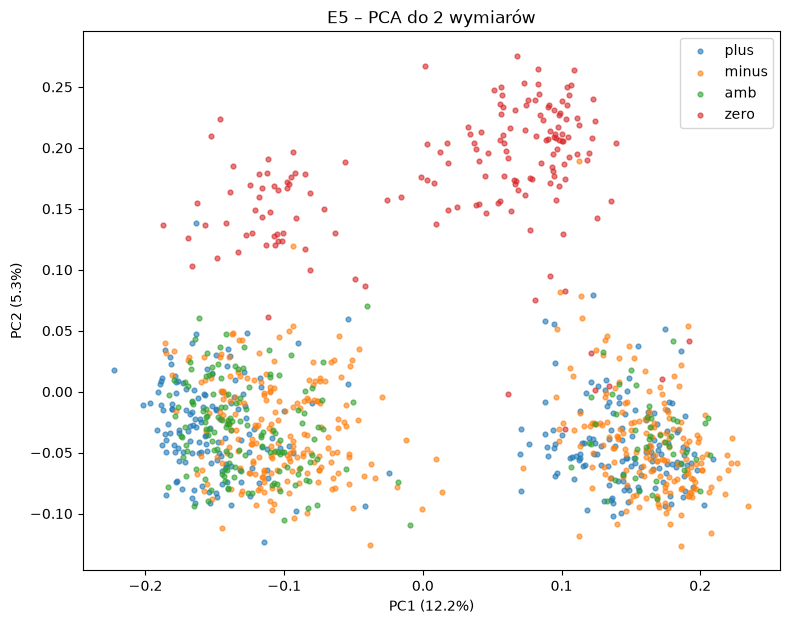

In [85]:
fig, ax = plt.subplots(figsize=(9, 7))

for label in ["plus", "minus", "amb", "zero"]:
    mask = labels == label
    ax.scatter(coords[mask, 0], coords[mask, 1], label=label, s=12, alpha=0.6)

ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
ax.set_title("E5 – PCA do 2 wymiarów")
ax.legend()
plt.show()

> Dwie pierwsze składowe wyjaśniają tylko 17.5% wariancji (PC1 = 12.2%, PC2 = 5.3%), więc wykres pokazuje niewielki wycinek przestrzeni.
>
> PC2 oddziela teksty `zero` - tworzy osobne skupiska u góry, wyraźnie oddzielone od reszty.
>
> PC1 dzieli dane na dwie grupy, lewą i prawą, zarówno wśród recenzji, jak i wśród `zero`. Prawdopodobnie odpowiada to podziałowi na tematykę hoteli i lekarzy.
>
> W obu skupiskach recenzji klasy `plus`, `minus` i `amb` całkowicie się mieszają.

In [86]:
for side, mask in [("lewa (PC1 < 0)", coords[:, 0] < 0), ("prawa (PC1 > 0)", coords[:, 0] > 0)]:
    pca_lookup = []
    for _, row in sample_df[mask].sample(8, random_state=RANDOM_STATE).iterrows():
        pca_lookup.append({
            "side": side,
            "text": row["text"]
        })

    display(pd.DataFrame(pca_lookup))
    print("=" * 100)

,side,text
0,lewa (PC1 < 0),Piękna lokalizacja ale . . . koszmarna obsługa - młodzi ludzie zachowujący się jak w ośrodku wypoczynkowym z czasów komuny - wynika to z braku kultury i szkoleń . . . SPA bardz...
1,lewa (PC1 < 0),"Po pierwsze ten hotel nie zasługuje na 4 * - łazienki jak z czasów PRLu , brud , syf i grzyb . Pokoje nienajgorsze , jednak zaniedbane - kanapy śmierdzące , ściany wymagające p..."
2,lewa (PC1 < 0),"Witam . W moich wizytach służbowych stanik na drodze właśnie ten hotel , cóż czasu się jak narazie jeszcze nie da cofnąć : ) pierwsze zaskoczenie parking płatny za dobę 14 zł ...."
3,lewa (PC1 < 0),"Nie polecam tego miejsca . Pokój był brudny . Mam wrażenie , że nie został odkurzony po pobycie ostatnich gości . Chusteczka , którą wytarła m wodę z podłogi w łazience zrobiła..."
4,lewa (PC1 < 0),"Budynek piękny , wspaniałe położony przy pieszym deptaku tuż przy parku . Niestety strasznie zaniedbany i fatalnie zarządzany . Wszystko do remontu i wymiany ! W pokoju telewiz..."
5,lewa (PC1 < 0),"Podróżuje bardzo dużo ale jeszcze nigdy nie spotkała m się z tak okropną atmosferą w hotelu stwarza człowiek , który tam rządzi . Personel jest zastraszony a pokoje trzeba ospu..."
6,lewa (PC1 < 0),Hotel został zamówiony z Bookingu . Przy rezerwacji podane zostały dane do karty za pomocą których hotel może pobrać należność . Rezerwacja została dokonana na 1 dobę w kwocie ...
7,lewa (PC1 < 0),"Bardzo przyjemne miejsce w kategorii wyglądu i lokalizacji . Idealne dla par i . . . emerytów - poza pałacem , miejscowość nie oferuje kompletnie nic . Obsługa na recepcji bard..."


,side,text
0,prawa (PC1 > 0),Nie polecam tego lekarza po całej kuracji silnymi antybiotykami na rzekomą candidę mój cały układ pokarmowy dostrzętnie się rozwalił . Zlecał mi badania do wszystkich możliwych...
1,prawa (PC1 > 0),Może i dobry specjalista ale zlewa pacjentów totalnie . Na 2 z 5 wizyt na których była m zasnął . Poza tym pomimo stwierdzonego w badaniu niskiego wyniku witamy D zalecił jej p...
2,prawa (PC1 > 0),"„ W naszym społeczeństwie , nawet wśród lekarzy , pokutuje wciąż przekonanie , że grypa jest mało groźną chorobą . Tymczasem nawet oficjalne dane są zaniżone , ponieważ faktycz..."
3,prawa (PC1 > 0),"Doktor niemiła , nie przepadam za wizytami u niej ( jesteśmy tylko w nagłych wypadkach , bo mamy najbliżej ) . Nieprawda , że lekarz zmęczony , to lekarz arogancki - my mamy ba..."
4,prawa (PC1 > 0),"Była m u tej lekarki prywatnie i nie mogę mieć zastrzeżeń , dostała m zwolnienie lekarskie bez problemu ( ciąża zagrożona ) . Niestety przy wizycie państwowo pani doktor już ni..."
5,prawa (PC1 > 0),"Ja jestem na nie , była to moja pierwsza wizyta jestem w 6 tyg . ciąży , została m potraktowana lekceważąco , mam wrażenie że jest to lekarz bardzo wyluuzowany . . . kiedy spyt..."
6,prawa (PC1 > 0),Pani dr Rudnicka jest wyniosła w stosunku do pacjentek i nie miła . Doświadczyła m tego leżąc na oddziale endokrynologii na Karowej . Nie można dowiedzieć się od niej żadnych i...
7,prawa (PC1 > 0),"Wspaniały lekarz . Pani doktor prowadziła moją pierwszą , bardzo wyczekaną ciążę . Podejście Pani doktor do pacjenta to pełen profesjonalizm . Nigdy wcześniej nie spotkał m tak..."


> Faktycznie po jednej stronie PC1 mamy tematykę hoteli a po drugiej lekarzy.

# Zadanie 8: Analiza przypadków

Proszę przygotować tabelę zawierającą co najmniej 12 przypadków, które pokazują ograniczenia reprezentacji wektorowych.

Pierwsze 6 przypadków należy znaleźć w wynikach najbliższych sąsiadów lub wyszukiwania. Powinny to być przykłady, w których podobieństwo jest wysokie, ale wynik jest problematyczny z punktu widzenia sentymentu lub intencji zapytania.

Kolejne 6 przypadków należy przygotować jako pary kontrastowe, np.:

```text
Hotel jest dobry.
Hotel nie jest dobry.
```

Dla każdej pary proszę policzyć podobieństwo w MiniLM i E5.

Tabela powinna zawierać:

| nr | typ | tekst A | tekst B / wynik | MiniLM | E5 | Δ MiniLM | Δ E5 | komentarz |
|---:|---|---|---|---:|---:|---:|---:|---|

Cosinusy E5 są skupione wysoko, więc nie wolno porównywać bezwzględnych wartości MiniLM i E5. Δ to różnica między cosinusem pary a cosinusem pary niezwiązanej tematycznie (np. "Hotel jest dobry." i "Samochód jest szybki.") liczonym tym samym modelem.

W komentarzu proszę używać krótkich kategorii, np.:

- negacja;
- wspólny temat;
- wspólne słownictwo;
- podobna forma;
- różny sentyment;
- bardzo krótki tekst;
- inna.


In [87]:
opposite = {"plus": "minus", "minus": "plus"}
rows, seen = [], set()

for row_id in range(len(labels)):
    if labels[row_id] not in opposite:
        continue
    ids, sims = get_neighbours(representations["E5"], row_id, k=5)
    for n_id, s in zip(ids, sims):
        pair = tuple(sorted((row_id, n_id)))
        if labels[n_id] == opposite[labels[row_id]] and pair not in seen:
            seen.add(pair)
            rows.append({"sim": s, "tekst A": sample_df.at[row_id, "text"], "tekst B": sample_df.at[n_id, "text"]})

top_df = pd.DataFrame(rows).nlargest(10, "sim")[["tekst A", "tekst B"]]
display(top_df)
data_pairs = list(top_df.itertuples(index=False, name=None))

,tekst A,tekst B
135,"Niestety , bardzo chciała m wystawić dobrą opinię Pani doktor , ponieważ szła m do niej na pierwszą wizytę z wielką nadzieją na pomoc . Kilka lat temu zdiagnozowano u mnie migr...","Ja do doktora Czapińskiego trafiła m 10 lat temu . Jestem mu wdzięczna za pomoc . Od bardzo dawna choruję na migrenę a dopiero podczas pierwszej wizyty dowiedziała m się , że m..."
106,Mogę jedynie pochwalić jedynie sprzątanie pokoi i dosyć niedużą odległość do morza około 400m - 5 min spacerkiem . Minusów jest jednak sporo : jedzenie było dobre jedynie do an...,"Właśnie wrócili śmy z tego Hotelu . Oceniam go bardzo dobrze , hotel czysty , zadbany , obsługa hotelowa też w porządku . Jedynym mankamentem były faktycznie wiecznie psujące s..."
61,"Była to moja pierwsza wizyta u endokrynologa . Po pozytywnych wpisach o Pani doktor była m pozytywnie nastawiona , ale odczuła m wrażenie , że Pani Joanna jest wyniosła i oboję...","Pani doktor anioł . . . ze świecą szukać w dzisiejszych czasach tak wspaniałych lekarzy . Przyszlam do pani dr z prośbą o konsultacje , bo miała m wrażenie że jestem źle leczon..."
18,Na wakacjach byli śmy w 4 dorosłe osoby . Lot z Warszawy bez problemów . Dojazd z lotniska zajął około 1 godzinę co przy mało klimatyzowanym autobusie było dużą ulgą . Na miejs...,Mogę jedynie pochwalić jedynie sprzątanie pokoi i dosyć niedużą odległość do morza około 400m - 5 min spacerkiem . Minusów jest jednak sporo : jedzenie było dobre jedynie do an...
34,"Ja osobiście polecam leczenie u Pani Doktor . Nie miała m straaasznie krzywych zębów , przynajmniej moim zdaniem , ale z przyczyn leczniczych po prostu musiała m założyć aparat...","Pani doktor jest miła , ale mało delikatna i niestety w moim przypadku sprawiła , że nieustannie czuję okropny ból , którego przed wizytą w gabinecie nigdy wcześniej nie odczuw..."
26,"Pani doktor bardzo zmieniła podejście do pacjenta . Po kilku udanych wizytach w poprzednich latach , dwie ostatnie bardzo oschłe , formalne i niesympatyczne . Bardzo przykre , ...",Pani lek . bardzo miła i sympatyczna . Była m u niej z córką i ma podejście do dzieci . Dała jej nawet małą nagrodę za to że była dzielna : ) Jesteśmy w trakcie leczenia i efek...
79,"Leczę się z powodu niepłodności od kilkunastu lat . Przechodziła m już dwie kliniki niepłodności , wielu lekarzy i kilkukrotne in vitro . Do Pani Doktor trafiła m przez przypad...",Absolutnie nie . Mój problem z którym postanowiła m przyjść do tego lekarza ciągnął się od roku . Natrafiła m na jego gabinet z polecenia i już chyba nigdy nie posłucham nikogo...
164,"Pominę już fakt , że Pan dr . miał obsuwę czasową 1 , 5 h . . . trudno , zdarza się . Potrzebowała m szybkiej i kompetentnej konsultacji lekarskiej , jednak się zawiodła m . Le...","Brakuje nie tyle dobrych , fachowych specjalistów co specjalistów z powołaniem a Pan dr bez wątpienia do nich należy . Drogi pacjencie pamiętaj o tym , iż Pan dr też jest człow..."
233,"Dziś był em u tego lekarza . Nie oceniam fachowości ale nie podobało mi się to bardzo że w lekarz nie miał dla mnie czasu , i zachowywał się jak by mnie nie było w ogóle , nie ...","Z historią moich zranień , głębokich , trudnych do zniesienia traum , mających korzenie w dzieciństwie , a potem tylko rozwijających się , bo aż do dorosłości , nie uświadomion..."
19,Na wakacjach byli śmy w 4 dorosłe osoby . Lot z Warszawy bez problemów . Dojazd z lotniska zajął około 1 godzinę co przy mało klimatyzowanym autobusie było dużą ulgą . Na miejs...,Hotel bez rewelacji . Wystarczy zostawiać dziennie kilka lirów na poduszce zeby każdego dnia był posprzątany dobrze i wymienione ręczniki . położenie hotelu świetne to chyba je...


In [88]:
contrast_pairs = [
    ("Hotel jest dobry.", "Hotel nie jest dobry."),
    ("Obsługa była bardzo miła.", "Obsługa była bardzo niemiła."),
    ("Śniadanie niezłe, ale pokój kiepski.", "Śniadanie kiepskie, ale pokój niezły."),
    ("Świetny hotel, polecam.", "Świetny hotel, pod warnukiem że lubisz jeść mrożonki."),
    ("Polecam.", "Nie polecam."),
    ("Lekarz pomógł mi wyleczyć moją chorobę.", "Lekarz pogorszył moją chorobę."),
    ("Hotel był lepszy, niż się spodziewałem.", "Hotel był gorszy, niż się spodziewałem."),
    ("Polecam ten hotel.", "Kiedyś polecałem ten hotel, ale już nie."),
    ("Hotel był w porządku.", "Hotel był rewelacyjny."),
    ("Lekarz był świetny.", "Hotel był świetny.")
]
formatted_list = [{"tekst A": a, "tekst B": b} for a, b in contrast_pairs]
display(pd.DataFrame(formatted_list))

all_pairs = data_pairs + contrast_pairs

,tekst A,tekst B
0,Hotel jest dobry.,Hotel nie jest dobry.
1,Obsługa była bardzo miła.,Obsługa była bardzo niemiła.
2,"Śniadanie niezłe, ale pokój kiepski.","Śniadanie kiepskie, ale pokój niezły."
3,"Świetny hotel, polecam.","Świetny hotel, pod warnukiem że lubisz jeść mrożonki."
4,Polecam.,Nie polecam.
5,Lekarz pomógł mi wyleczyć moją chorobę.,Lekarz pogorszył moją chorobę.
6,"Hotel był lepszy, niż się spodziewałem.","Hotel był gorszy, niż się spodziewałem."
7,Polecam ten hotel.,"Kiedyś polecałem ten hotel, ale już nie."
8,Hotel był w porządku.,Hotel był rewelacyjny.
9,Lekarz był świetny.,Hotel był świetny.


In [89]:
def cos_pair(model_name: str, a: str, b: str) -> float:
    prefix = "query: " if model_name == "E5" else ""
    vecs = models[model_name].encode([prefix + a, prefix + b])
    return float(cosine_sim(vecs)[0, 1])

unrelated = {m: cos_pair(m, "Hotel jest dobry.", "Samochód jest szybki.") for m in ["MiniLM", "E5"]}
print(unrelated)

{'MiniLM': 0.13979412615299225, 'E5': 0.8339742422103882}


In [90]:
cases = pd.DataFrame(all_pairs, columns=["tekst A", "tekst B / wynik"])
cases.insert(0, "nr", range(1, len(cases) + 1))
cases.insert(1, "typ", ["dane"] * len(data_pairs) + ["kontrast"] * len(contrast_pairs))

for m in ["MiniLM", "E5"]:
    cases[m] = [cos_pair(m, a, b) for a, b in all_pairs]
    cases[f"Δ {m}"] = cases[m] - unrelated[m]

cases = cases[["nr", "typ", "tekst A", "tekst B / wynik", "MiniLM", "E5", "Δ MiniLM", "Δ E5"]]

cases["komentarz"] = [
    "wspólny temat, różny sentyment",
    "wspólny temat, różny sentyment",
    "wspólne słownictwo, różny sentyment",
    "wspólny temat, różny sentyment",
    "wspólny temat, różny sentyment",
    "wspólne słownictwo, różny sentyment",
    "wspólny temat, różny sentyment",
    "wspólny temat, różny sentyment",
    "podobna forma, różny sentyment",
    "wspólne słownictwo, różny sentyment",
    "negacja",
    "negacja (antonim), różny sentyment",
    "wspólne słownictwo, podobna forma",
    "inna (ironia), wspólne słownictwo",
    "bardzo krótki tekst, negacja",
    "podobna forma, różny sentyment",
    "negacja (antonim), różny sentyment",
    "negacja, inna (zmiana opinii w czasie)",
    "podobna forma, inna (natężenie sentymentu)",
    "inna (ten sam sentyment, inny temat)",
]

with pd.option_context("display.max_colwidth", None):
    display(cases.round(3))

,nr,typ,tekst A,tekst B / wynik,MiniLM,E5,Δ MiniLM,Δ E5,komentarz
0,1,dane,"Niestety , bardzo chciała m wystawić dobrą opinię Pani doktor , ponieważ szła m do niej na pierwszą wizytę z wielką nadzieją na pomoc . Kilka lat temu zdiagnozowano u mnie migrenę , która zdominowała moje życie codzienne . Powiedziała m o tym Pani doktor , że migreny wróciły z podwójną siłą po ciąży i u neurloga nie była m kilka lat , leczyła m się tylko doraźnie . Bała m się , że może to być coś innego , groźniejszego , bo zwiększyło się natężenie i umiejscowienie bólu . Wiem jak wygląda badanie neurologiczne i badanie u Pani doktor było jakąś 1 / 10 tego , jak badali mnie inni lekarze , mimo tego , że nie jest to skomplikowane badanie . Leki miała m wrażenie , że wybrała m sobie sama , a na doraźny ból głowy dostała m m . in . lek bez recepty z reklamy , który dla prawdziwych migreników jest jak placebo . Nie dostała m żadnych dodatkowych badań , a skierowanie na rezonans dostała m "" jak Pani chce ? "" . Prawdopodobnie Pani doktor jest bardzo dobrym specjalistą , ale w innych odłamach neurologii . Nie śmiem także podważać jej kompetencji , po prostu mam porównanie i czuję się bardzo zlekceważona i rozczarowana moją wizytą , bo bardzo liczyła m na pomoc .","Ja do doktora Czapińskiego trafiła m 10 lat temu . Jestem mu wdzięczna za pomoc . Od bardzo dawna choruję na migrenę a dopiero podczas pierwszej wizyty dowiedziała m się , że można to jakoś leczyć ! Bardzo cierpiała m wcześniej , mieszkam w Rzeszowie i tutaj nikt z lekarzy neurologów ( a było ich sporo ) nie potrafił mi pomóc . Kiedy opowiadała m im o swoich objawach chorobowych , niektórzy potrafili się nawet wyśmiewać ! Przepisywali mi jakieś dziwne , nieskuteczne leki . . ( teraz jak słyszę w reklamie że na migrenę apap to mi się śmiać chce heh . . ) Nikomu nie życzę na to chorować ! Kiedy na własnym ślubie nawet dostała m migrenę tuż przed wyjściem do kościoła , powiedziała m wtedy dość ! Po kilku tygodniach trafiła m do Czapińskiego i w końcu zaczęła m leczenie i normalne życie ! Migreny pojawiały się rzadziej . . Mogła m już złagodzić okropny ból dzięki lekom ! Teraz jestem młodą mamą ! Migreny na razie nie mam ! Miejmy nadzieję , że się wyciszyła ! Czasem tak bywa czasem nie . . A wracając do tematu . . Wiem , że wizyty u Dr Czapińskiego są drogie i jeszcze leki trzeba wykupić ale ja nie żałuję , że skorzystała m i do dziś jestem mu wdzięczna za pomoc .",0.800,0.945,0.660,0.111,"wspólny temat, różny sentyment"
1,2,dane,"Mogę jedynie pochwalić jedynie sprzątanie pokoi i dosyć niedużą odległość do morza około 400m - 5 min spacerkiem . Minusów jest jednak sporo : jedzenie było dobre jedynie do ankiety , w której widocznie zbyt dużo osób pochwaliło kuchnie . Napoje dozowane z dystrybutorów wykonane są z koncentratu niskiej jakości , . na które mieli śmy alergię - żona miała mocną wysypkę na rekach . Piwo rozcieńczone wodą ( raz z rana dostał em wodę która nie miała koloru piwa - nieprzeszkolona barmanka nie umiała wyregulować dozownika ) , drinki na najtańszych lokalnych alkoholach , po wypiciu kilku działały jak środek nasenny . Nie da się tym upić nawet na słońcu . Łazienki ogólnodostępne były brudne , a smród z nich czuć było na korytarzu . Przy basenie leżaki - brązowe aluminiowe z żyłkową tkaniną bardzo niewygodne i wiecznie brudne nie widział em , przez 10 dni aby ktoś je mył . Leżaków na słońcu oczywiście brakowało więc trzeba było rezerwować leżaki ręcznikami do godziny 8 . 30 . Po 9 . 00 zostawała tylko plaża . Dwa razy zniknęły mi ręczniki przy basenie gdy poszli śmy na śniadanie - szczyt chamstwa . Więc kto się na ten hotel zdecyduje przestrzegam . Internet lobby porażka , płatny jest tylko na jedno urządzenie , cały internet jest przez serwer więc nie da się tego oszukać . Prędkość jest również kiepska , ale jak się zepsuje pogoda to można pooglądać jedynie pliki tekstowe , bo pliki wideo non stop się cięły . Cena WI - FI - 32 - lewa tydzień , 50 - lewa 10 dni . W pokojach w łazienk

> Wszystkie przypadki z danych (nr 1–10) mają kategorię „różny sentyment”, bo celowo wybierałem pary plus–minus o najwyższym podobieństwie w E5. <br>
> E5 daje tym parom podobieństwo ok. 0.93–0.95, mimo przeciwnego sentymentu. Wynika ono ze wspólnego tematu albo nawet tylko z formy: nr 9 (zła wizyta u alergologa i pozytywna relacja z terapii) MiniLM ocenia nisko (0.33), a E5 nadal na 0.93. MiniLM ocenia te pary różnie (0.33–0.80), najwyżej te o tym samym podtemacie (migrena, ortodonta, leczenie niepłodności).
>
> Zamiana słów (nr 13) jest niewidoczna dla obu modeli (~0.98), a natężenie sentymentu też (nr 19: „w porządku” / „rewelacyjny”, MiniLM 0.86).
>
> Jedno słowo z przeciwnym sentymentem, „miła/niemiła” (nr 12), MiniLM rozpoznaje (0.13), a E5 nie (0.98). Antonim w porównaniu, „lepszy/gorszy” (nr 17), nie rozpoznaje już żaden model.
>
> Dla MiniLM temat waży więcej niż sentyment: „Lekarz był świetny.” / „Hotel był świetny.” (nr 20, 0.35) jest mniej podobne niż „Hotel jest dobry.” / „Hotel nie jest dobry.” (nr 11, 0.55).
>
> Ironia (nr 14) myli oba modele: początek „Świetny hotel” dominuje nad sensem całości. Najlepiej E5 radzi sobie z dłuższą negacją (nr 18, Δ = 0.03), ale nawet wtedy nie schodzi poniżej pary niezwiązanej.

# Zadanie 9: Interpretacja wyników

To zadanie nie wymaga nowej implementacji.

Na podstawie wyników zadań 1-8 proszę odpowiedzieć:

1. W jakich sytuacjach TF-IDF zachowywał się lepiej od reprezentacji gęstych?
2. W jakich sytuacjach przewagę miały MiniLM lub E5?
3. Czy wysoka wartość `purity@k` oznacza, że reprezentacja jest ogólnie "lepsza semantycznie"?
4. Czy model o najlepszym `Precision@10` musi być najlepszym wyborem do klasyfikacji sentymentu?
5. Jakie dwa ograniczenia eksperymentu najbardziej wpływają na interpretację wyników?

Odpowiedzi powinny odwoływać się do uzyskanych liczb i przykładów.

**1. Kiedy TF-IDF był lepszy od reprezentacji gęstych?**
> Był lepszy pod względem kosztu czasowego - 0.2 ms/dokument na CPU wobec 0.5–1.1 ms na GPU dla embeddingów (zad. 3). Również gdy zapytanie dzieli konkretne słowa z dokumentami: dla zapytania `minus` o lekarzu P@5 = 1.0, więcej niż E5 (zad. 6). TF-IDF nie ma też problemu z limitem długości tekstu, a MiniLM obcina 76.7% recenzji (zad. 2).

**2. Kiedy przewagę miały MiniLM lub E5?**
> Największa przewaga była widoczna przy parafrazach takich jak „Hotel był bardzo dobry” i „Obiekt noclegowy zrobił świetne wrażenie”, które mają w TF-IDF podobieństwo 0, a embeddingi stawiają tę parę na pierwszym miejscu (zad. 2). E5 najlepiej grupuje dokumenty po etykiecie: purity@5 = 0.665 wobec 0.559 dla TF-IDF, a największa przewaga jest dla `plus` (0.658 wobec 0.476) (zad. 5). MiniLM jako jedyny odróżnił „miła” od „niemiła” (0.13 wobec 0.98 w E5) (zad. 8).

**3. Czy wysoka purity@k oznacza reprezentację „lepszą semantycznie”?**
> Nie. Purity mierzy tylko zgodność etykiet sąsiadów. Najwyższą purity ma klasa `zero`, ale wynika to z innego gatunku tekstu (artykuły), a nie z rozumienia sentymentu (zad. 5, 7). PCA pokazuje, że główne kierunki E5 kodują domenę i gatunek, a `plus`, `minus` i `amb` całkowicie się mieszają (zad. 7).

**4. Czy model z najlepszym Precision@10 musi być najlepszy do klasyfikacji sentymentu?**
> Nie. Najlepsze P@10 ma E5 (0.588), ale MiniLM ma 0.575, a TF-IDF 0.500, więc przy 8 zapytaniach różnice są w granicach szumu (zad. 6). Poza tym P@10 sprawdza tylko kilka wymyślonych zapytań, a do klasyfikacji model musi odróżniać sentyment, tymczasem E5 uznaje „Obsługa była bardzo miła” i „…niemiła” za niemal identyczne (0.98, zad. 8).

**5. Dwa ograniczenia, które najbardziej wpływają na interpretację**
> * O trafności wyników w naszych eksperymentach decydowała prawie zawsze tylko etykieta sentymentu, a nie to, czy dokument faktycznie pasuje treścią. Do tego klasa `zero` to w praktyce inny rodzaj tekstów, a `amb` trudno jednoznacznie ocenić nawet człowiekowi, więc wyniki dla tych klas są bardziej zależne od samych danych niż jakości modelu.
> * Mała skala: 8 zapytań, 3 dokumenty w analizie sąsiadów i jedna para odniesienia dla Δ. Wiele różnic mieści się w granicach szumu (zad. 4, 6, 8).

# Zadanie 10: Decyzja projektowa

To zadanie nie wymaga nowej implementacji.

Proszę wybrać reprezentację dla każdego z trzech zastosowań:

1. szybkie wyszukiwanie po dokładnych nazwach i terminach;
2. wyszukiwanie semantyczne parafraz;
3. przyszły system RAG.

Dla każdego zastosowania proszę podać:

- wybraną reprezentację;
- jeden wynik ilościowy (jakość lub koszt) uzasadniający decyzję;
- jeden obserwowany przypadek błędu lub ograniczenie;
- koszt, który należy zaakceptować.

Na końcu proszę odpowiedzieć jednym akapitem na pytanie:

**Dlaczego embeddingu nie należy utożsamiać ze "znaczeniem tekstu"?**

**1. Szybkie wyszukiwanie po dokładnych nazwach i terminach → TF-IDF**
> - Wynik: 0.2 ms/dokument na CPU, 1.13 MB dla 1000 dokumentów (zad. 3); dopasowanie po konkretnych słowach, np. zapytanie `minus` o lekarzu P@5 = 1.0 (zad. 6).
> - Ograniczenie: nie rozpoznaje parafraz, „hotel” i „obiekt noclegowy” mają podobieństwo 0 (zad. 1).
> - Koszt: brak synonimów i odmiany, więc „hotel” i „hotelu” to różne słowa.

**2. Wyszukiwanie semantyczne parafraz → MiniLM**
> - Wynik: najwyraźniej oddziela parafrazę od reszty (A-B 0.749 wobec A-C 0.378, zad. 2), a w wyszukiwaniu ma P@5 = 0.600, tyle samo co E5 (zad. 6), przy 2× krótszym czasie (0.52 vs 1.07 ms/dokument, zad. 3).
> - Ograniczenie: obcina 76.7% recenzji do 128 tokenów (zad. 2), a ironię uznaje za podobną do pochwały (0.84, zad. 8).
> - Koszt: model szuka podobnego sensu, więc konkretna nazwa, numer czy termin może przegrać z tekstem o podobnym temacie, który tej nazwy w ogóle nie zawiera.

**3. Przyszły system RAG → E5**
> - Wynik: najlepsza purity@5 = 0.665 (zad. 5) i najwyższe P@10 = 0.588 (zad. 6, choć w granicach szumu), a okno 512 tokenów obcina tylko 3.7% tekstów (zad. 2). W RAG dokumenty są długie, a MiniLM widziałby tylko początek 76.7% z nich.
> - Ograniczenie: benchmark wyszukiwania mierzy zgodność sentymentu, a nie trafność treści, której potrzebuje RAG. Nie odróżnia też negacji („miła” / „niemiła” = 0.98, zad. 8), a podobieństwa są ściśnięte (ok. 0.83–0.98; nawet para niezwiązana tematycznie ma 0.83, zad. 8), więc trudno ustalić próg trafności.
> - Koszt: 2× wolniejszy od MiniLM (1.07 ms/dokument), a dokumenty trzeba dodatkowo kodować używając prefixów.

Dlaczego embeddingu nie należy utożsamiać ze „znaczeniem tekstu”?

> Embedding to wektor, który model nauczył się tworzyć tak, żeby podobne teksty były blisko siebie, ale „podobne” oznacza tu głównie wspólny temat i styl. W wynikach dwie pierwsze składowe PCA dla E5 rozdzielały domenę (hotele i lekarze) oraz gatunek (artykuły i recenzje), a sentyment w ogóle nie był widoczny. E5 uznał „Obsługa była bardzo miła” i „Obsługa była bardzo niemiła” za niemal identyczne (0.98). MiniLM w 77% przypadków widzi tylko początek recenzji. Embedding oddaje więc te tylko rzeczy, których model nauczył się podczas treningu, i może pomijać negację, ironię czy wydźwięk, które dla konkretnego zadania są najważniejsze.

# Karta modelu embeddingowego

Proszę wybrać jeden z dwóch modeli gęstej reprezentacji jako model rekomendowany do dalszych laboratoriów i utworzyć:

```text
artifacts/embedding_model_card.md
```

Karta powinna zawierać:

## Model
- nazwa checkpointu;
- wymiar reprezentacji;
- sposób normalizacji;
- wymagane prefiksy wejścia, jeśli dotyczy.

## Dane
- użyty zbiór;
- wielkość próbki;
- odsetek tekstów obciętych przez okno modelu;
- sposób doboru próbki.

## Koszt
- czas utworzenia reprezentacji;
- ms/dokument;
- rozmiar reprezentacji w pamięci.

## Jakość sąsiedztwa
- `purity@1`;
- `purity@5`;
- `purity@10`.

## Wyszukiwanie
- `Precision@5`;
- `Precision@10`.

## Analiza jakościowa
- najważniejsze obserwacje z PCA;
- dominujące typy błędów z analizy 20 przypadków.

## Zastosowanie
- do jakich zadań model jest rekomendowany;
- do jakich zadań nie należy go wybierać wyłącznie na podstawie tego laboratorium.

## Ograniczenia
- ograniczenia danych;
- ograniczenia benchmarku;
- ograniczenia samej reprezentacji.


# Wnioski

Na koniec pracy proszę zapisać krótkie wnioski. Każdy wniosek powinien wynikać z wykonanego eksperymentu i zawierać odwołanie do wyniku liczbowego, obserwacji albo konkretnego przypadku.

Nie należy przepisywać definicji TF-IDF, embeddingów ani podobieństwa cosinusowego.

> 1. Podobieństwo w TF-IDF to wspólne słowa, a nie wspólne znaczenie. „Hotel był bardzo dobry” i „Hotel był bardzo zły” mają podobieństwo 0.634, a parafraza „Obiekt noclegowy zrobił świetne wrażenie” ma 0. Embeddingi odwracają tę kolejność: dla MiniLM parafraza ma 0.749, a para o przeciwnym sentymencie 0.378.

> 2. Wartości cosinusa nie da się porównywać między modelami. E5 daje prawie wszystkim parom 0.83–0.98, nawet zdaniom bez związku („Hotel jest dobry.” / „Samochód jest szybki.” = 0.83). Dla MiniLM ta sama para ma 0.14. Między modelami można porównywać tylko kolejność albo Δ względem pary odniesienia.

> 3. Wymiar reprezentacji nie mówi o koszcie. TF-IDF ma 15 649 wymiarów, a zajmuje 1.13 MB, mniej niż embeddingi o 384 wymiarach (1.47 MB), bo ponad 99% wartości to zera. Jest też najszybszy: 0.2 ms/dokument na CPU wobec 0.5 (MiniLM) i 1.1 ms (E5) na GPU.

> 4. Okno modelu ma duże znaczenie przy długich recenzjach. MiniLM obcina 76.7% tekstów z próbki do 128 tokenów, E5 tylko 3.7%. MiniLM jest szybszy głównie dlatego, że czyta mniej tekstu.

> 5. Embeddingi grupują teksty głównie po temacie i gatunku, a nie po sentymencie. W PCA dla E5 pierwsze składowe oddzielają hotele od medycyny i artykuły (`zero`) od recenzji, a `plus`, `minus` i `amb` się mieszają. Najwyższa purity@5 klasy `zero` (0.825) wynika z innego gatunku tekstu, a nie z rozumienia sentymentu.

> 6. Różnice w wyszukiwaniu są dużo mniejsze niż w purity. E5 wyraźnie wygrywa w purity (purity@5 0.665 wobec 0.580 dla MiniLM i 0.559 dla TF-IDF), a w wyszukiwaniu wszystkie trzy reprezentacje są w granicach szumu (P@10 0.588 / 0.575 / 0.500). Wynik benchmarku zależy mocno od pojedynczych zapytań: dwa zapytania `zero` dają P@5 0.8–1.0 i 0.2–0.4.

> 7. Żaden model nie radzi sobie spójnie z negacją, antonimami i ironią. MiniLM odróżnił „Obsługa była bardzo miła” od „…niemiła” (0.13, Δ = −0.01, czyli poziom pary niezwiązanej), ale już „Hotel jest dobry.” / „Hotel nie jest dobry.” ocenił wyraźnie powyżej odniesienia (0.55, Δ = 0.41), a ironię uznał za bliską pochwale (0.84). E5 daje wszystkim parom kontrastowym podobieństwo wyższe niż parze niezwiązanej (Δ = 0.03–0.15, np. miła/niemiła = 0.98). Zamiana ról słów nie zmienia podobieństwa w żadnym modelu (~0.98). Klasa `amb` ma najniższą purity we wszystkich reprezentacjach (0.25–0.33), bo łączy ze sobą sentyment pozytywny i negatywny.

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [x] własną implementację eksperymentu TF-IDF i podobieństwa cosinusowego;
- [x] reprezentacje MiniLM i E5;
- [x] deterministyczną próbkę danych;
- [x] benchmark czasu i pamięci trzech reprezentacji;
- [x] implementację wyszukiwania najbliższych sąsiadów;
- [x] `purity@1`, `purity@5`, `purity@10`;
- [x] osiem zapytań w benchmarku wyszukiwania;
- [x] własną implementację `Precision@k`;
- [x] `Precision@5` i `Precision@10`;
- [x] wizualizację PCA;
- [x] tabelę 20 przypadków błędów i par kontrastowych;
- [x] sprawdzenie okna modeli (`max_seq_length`) i odsetka obciętych tekstów;
- [x] purity z punktem odniesienia (losowi sąsiedzi) i per klasa;
- [x] odpowiedzi do zadania interpretacyjnego (Zadanie 9);
- [x] plik `artifacts/embedding_model_card.md`;
- [x] od pięciu do ośmiu wniosków końcowych.